# Семинар 8. Нейроранжирование: DCN v2 и CatBoost

Предсказываем клик по 13 числовым и 26 категориальным признакам Criteo.
Сравним MLP, MLP с Piecewise Linear Encoding (PLE), DCN v2 и CatBoost.
Модель выдаёт один logit на показ; обучаем её с бинарной кросс-энтропией.


## Запуск

В Colab выберите **Среда выполнения → Сменить среду выполнения → T4 GPU**,
затем **Выполнить все**. Данные скачаются в `/content/criteo_neural`.

Берём 1 000 000 показов для обучения, 250 000 для валидации и 200 000 из
отдельного тестового дня. Размер выборки задаётся в следующей ячейке.


In [21]:
%pip -q install "polars==1.35.2" "catboost==1.2.10" "tqdm>=4.66,<5"


In [22]:
import json, time, gc, random, platform
from pathlib import Path
import numpy as np
import pandas as pd
import polars as pl
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score, log_loss
import catboost as cb
SEED = 42
TRAIN_ROWS = 1_250_000
TEST_ROWS = 200_000
EPOCHS = 5
BATCH_SIZE = 4096
import matplotlib.pyplot as plt
from IPython.display import display
from tqdm.auto import tqdm
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
assert torch.cuda.is_available(), 'Select Runtime → Change runtime type → T4 GPU'
torch.set_num_threads(2)
device = torch.device('cuda')
print('GPU:', torch.cuda.get_device_name(0))
print('Versions:', {'torch':torch.__version__, 'polars':pl.__version__, 'catboost':cb.__version__})
print('Python:',platform.python_version())

GPU: Tesla T4
Versions: {'torch': '2.11.0+cu130', 'polars': '1.35.2', 'catboost': '1.2.10'}
Python: 3.13.16


## Данные

[Criteo Kaggle Dataset](https://www.kaggle.com/datasets/dogrose/downsampled-criteo-kaggle-dataset/data):
`label` — клик, `I1–I13` — числовые признаки, `C1–C26` — категории в hex.

Пропуски чисел заполняем нулём. Затем берём `log(x + 1)`, а для `I2` —
`log(x + 4)`, поскольку в нём встречаются отрицательные значения.
Пропуски категорий кодируем ID 0.

Из файла за шесть дней случайно выбираем 1 250 000 строк и делим их в пропорции
80/20 с сохранением доли кликов. Квантили PLE и параметры нормализации считаем
по train. По validation выбираем эпоху нейросети и итерацию CatBoost.
Файл за последний день оставляем для теста.


In [23]:
import subprocess, zipfile, shutil
DATA = Path('/content/criteo_neural')
DATA.mkdir(exist_ok=True)
archive = DATA / 'criteo.zip'
if not (DATA / 'criteo_train_6days_downsampled.parquet').exists():
    subprocess.run(['curl','--fail','--location','--retry','3','--output',str(archive),'https://www.kaggle.com/api/v1/datasets/download/dogrose/downsampled-criteo-kaggle-dataset'],check=True)
    with zipfile.ZipFile(archive) as z:
        for name in ['criteo_train_6days_downsampled.parquet','criteo_test_1day_downsampled.parquet']:
            with z.open(name) as source, (DATA/name).open('wb') as destination:
                shutil.copyfileobj(source,destination)
for name in ['criteo_train_6days_downsampled.parquet','criteo_test_1day_downsampled.parquet']:
    assert (DATA/name).is_file(), name
print('Dataset ready')

Dataset ready


In [24]:
class CriteoDatasetUtils:
    INT_COLS = [f'I{i + 1}' for i in range(13)]
    CAT_COLS = [f'C{i + 1}' for i in range(26)]
    LABEL_COL = 'label'

    @classmethod
    def preprocess_dense_features(cls, lf: pl.LazyFrame) -> pl.LazyFrame:
        expressions = []
        for col in cls.INT_COLS:
            expressions.append(
                pl.col(col).fill_null(0).add(1 if col != 'I2' else 4).log()
            )
        return lf.with_columns(expressions)

    @classmethod
    def preprocess_categorical_features(cls, lf: pl.LazyFrame) -> pl.LazyFrame:
        expressions = []
        for col in cls.CAT_COLS:
            expressions.append(
                pl.col(col).fill_null('00000000').str.to_integer(base=16)
            )
        return lf.with_columns(expressions)

    @classmethod
    def read_and_preprocess(cls, path: str) -> pl.DataFrame:
        lf = pl.scan_parquet(path)
        lf = cls.preprocess_categorical_features(lf)
        lf = cls.preprocess_dense_features(lf)
        return lf.collect()

In [25]:
def read_sample(path, rows, seed):
    lf = pl.scan_parquet(path)
    total = lf.select(pl.len()).collect().item()
    idx = np.sort(np.random.default_rng(seed).choice(total, min(rows,total), replace=False)).astype(np.uint32)
    lf = lf.with_row_index('_row').filter(pl.col('_row').is_in(pl.Series(idx).implode())).drop('_row')
    lf = CriteoDatasetUtils.preprocess_categorical_features(lf)
    lf = CriteoDatasetUtils.preprocess_dense_features(lf)
    return lf.collect()

all_train = read_sample(DATA/'criteo_train_6days_downsampled.parquet',TRAIN_ROWS,SEED)
test_df = read_sample(DATA/'criteo_test_1day_downsampled.parquet',TEST_ROWS,SEED+1)
train_idx, val_idx = train_test_split(np.arange(len(all_train)),test_size=0.2,random_state=SEED,stratify=all_train['label'].to_numpy())
train_df, val_df = all_train[train_idx], all_train[val_idx]
del all_train
for name, frame in [('train',train_df),('validation',val_df),('test',test_df)]:
    assert sum(frame.null_count().row(0)) == 0
    assert np.isfinite(frame[CriteoDatasetUtils.INT_COLS].to_numpy()).all()
    print(name,frame.shape,'CTR',frame['label'].mean())

train (1000000, 40) CTR 0.255554
validation (250000, 40) CTR 0.255556
test (200000, 40) CTR 0.25876


### Почему отдельные эмбеддинги дороги

Если у каждого поля свой словарь $V_t$, то таблицы содержат
$\sum_t |V_t|d$ параметров. Для FP32-весов, градиентов и двух состояний Adam
нужно примерно 16 байт на параметр. Это оценка без активаций и временных буферов.
Посчитаем её по обучающей выборке.

In [26]:
cardinalities = train_df.select(pl.col(CriteoDatasetUtils.CAT_COLS).n_unique())
display(cardinalities.transpose(include_header=True,header_name='field',column_names=['unique_ids']).sort('unique_ids',descending=True))
unique_total=sum(cardinalities.row(0))
print(f'Separate embeddings, d=64: {unique_total*64*16/1024**3:.2f} GiB with Adam')
print(f'Shared table, 131072 × 16: {131072*16*16/1024**3:.3f} GiB with Adam')

field,unique_ids
str,u32
"""C3""",359890
"""C12""",320332
"""C21""",288729
"""C16""",244922
"""C4""",140481
…,…
"""C22""",16
"""C23""",14
"""C17""",10


Separate embeddings, d=64: 1.43 GiB with Adam
Shared table, 131072 × 16: 0.031 GiB with Adam


## Общая таблица эмбеддингов

Вместо отдельной таблицы на каждый словарь заведём одну таблицу из $M$ строк.
Хешируем пару «поле, значение», извлекаем эмбеддинг и конкатенируем векторы
в порядке полей. При двух хешах у каждой категории будет два вектора.

Хеши вида `h_j(v) = (v + seed_j) % M` сохраняют одну и ту же коллизию:
`v` и `v + M` совпадут при любом `seed_j`. В примере ниже это видно на числах.
Используем SplitMix64 с разными солями поля и хеша. NumPy `uint64` выполняет
арифметику по модулю $2^{64}$. Хешируем данные один раз перед обучением.

Источник: [Unified Embedding](https://arxiv.org/abs/2305.12102).


In [27]:
class MultihashTransform:
    """CPU preprocessing: SplitMix64 for each (field, value, hash seed)."""

    def __init__(self, cardinality, seeds, name='sparse'):
        if cardinality < 2:
            raise ValueError('cardinality must be at least 2')
        self.cardinality = cardinality
        self.seeds = np.asarray(seeds, dtype=np.uint64)
        if self.seeds.ndim != 2 or self.seeds.shape[1] == 0:
            raise ValueError('seeds must have shape (fields, hashes)')
        self.name = name

    def __call__(self, sample):
        values = sample[self.name].numpy().astype(np.uint64)
        if values.shape[-1] != len(self.seeds):
            raise ValueError('Unexpected number of categorical fields')
        fields = np.arange(len(self.seeds), dtype=np.uint64)[:, None]
        salt = fields * np.uint64(0x9E3779B97F4A7C15) + self.seeds
        mixed = values[..., None] ^ salt
        mixed = mixed + np.uint64(0x9E3779B97F4A7C15)
        mixed = (mixed ^ (mixed >> 30)) * np.uint64(0xBF58476D1CE4E5B9)
        mixed = (mixed ^ (mixed >> 27)) * np.uint64(0x94D049BB133111EB)
        mixed = mixed ^ (mixed >> 31)
        ids = (mixed % np.uint64(self.cardinality)).astype(np.int64)
        shape = values.shape[:-1] + (-1,)
        sample[self.name] = torch.from_numpy(ids.reshape(shape))
        return sample

In [28]:
M = 1024
seeds = [[17,31],[23,47]]
x = torch.tensor([123,456])
old_a = (x[:,None]+torch.tensor(seeds)) % M
old_b = ((x+M)[:,None]+torch.tensor(seeds)) % M
hasher = MultihashTransform(M,seeds)
new_a=hasher({'sparse':x})['sparse']
new_b=hasher({'sparse':x+M})['sparse']
print('Shift hashes:',old_a.flatten().tolist(),old_b.flatten().tolist())
print('Mixed hashes:',new_a.tolist(),new_b.tolist())
assert torch.equal(old_a,old_b)
assert not torch.equal(new_a,new_b)

Shift hashes: [140, 154, 479, 503] [140, 154, 479, 503]
Mixed hashes: [914, 324, 570, 450] [742, 869, 808, 883]


## Piecewise Linear Encoding

Разобьём диапазон числового признака на интервалы с границами
$b_0<\dots<b_T$. В текущем интервале координата равна
$(x-b_{t-1})/(b_t-b_{t-1})$. Пройденные интервалы дают 1, следующие — 0.
На графике ниже показано кодирование с двумя интервалами.

Первый интервал продолжаем ниже 0, последний — выше 1. Если интервал один,
продолжаем его в обе стороны. Границы берём по квантилям train, совпавшие
границы объединяем. Константные признаки и пустые координаты кодируем нулями.

Источник: [On Embeddings for Numerical Features in Tabular Deep Learning](https://arxiv.org/abs/2203.05556).


In [29]:
class PiecewiseLinearEncodingTransform:
    """Train-only quantile bins; extrapolate in the first and last intervals."""

    def __init__(self, dense_train_df, n_bins=16, name='dense'):
        if n_bins < 1:
            raise ValueError('n_bins must be positive')
        self.name = name
        train = torch.tensor(dense_train_df.to_numpy(), dtype=torch.float32)
        if train.ndim != 2 or len(train) == 0 or not torch.isfinite(train).all():
            raise ValueError('Training features must be nonempty and finite')
        quantiles = torch.quantile(train, torch.linspace(0, 1, n_bins + 1), dim=0)
        self.bins = [column.unique() for column in quantiles.T]
        self.n_bins = [max(1, len(edges) - 1) for edges in self.bins]
        width = max(self.n_bins)
        self.left = torch.zeros(train.shape[1], width)
        self.width = torch.ones_like(self.left)
        self.valid = torch.zeros_like(self.left, dtype=torch.bool)
        self.first = torch.zeros_like(self.valid)
        self.last = torch.zeros_like(self.valid)
        for field, edges in enumerate(self.bins):
            count = len(edges) - 1
            if count == 0:
                continue
            self.left[field, :count] = edges[:-1]
            self.width[field, :count] = edges.diff()
            self.valid[field, :count] = True
            self.first[field, 0] = True
            self.last[field, count - 1] = True

    def __call__(self, sample):
        x = sample[self.name].float()
        encoded = (x[..., None] - self.left) / self.width
        # First bin can go below zero; last bin can go above one.
        encoded = torch.where(self.first, encoded, encoded.clamp_min(0))
        encoded = torch.where(self.last, encoded, encoded.clamp_max(1))
        encoded = torch.where(self.valid, encoded, 0.)
        sample[self.name] = encoded.flatten(-2)
        return sample

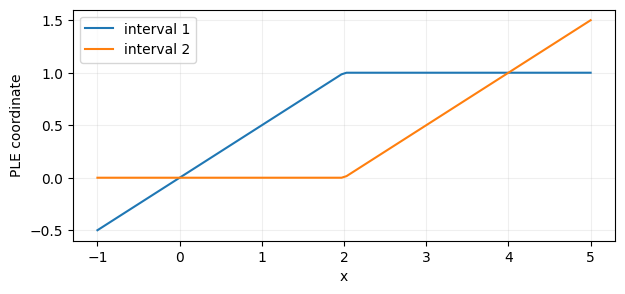

In [30]:
toy=pl.DataFrame({'x':[0.,1.,2.,3.,4.],'constant':[7.]*5})
toy_ple=PiecewiseLinearEncodingTransform(toy,n_bins=2)
grid=torch.linspace(-1,5,100)
values=torch.stack([grid,torch.full_like(grid,7.)],dim=1)
encoded=toy_ple({'dense':values})['dense']
plt.figure(figsize=(7,3))
plt.plot(grid,encoded[:,0],label='interval 1')
plt.plot(grid,encoded[:,1],label='interval 2')
plt.xlabel('x');plt.ylabel('PLE coordinate');plt.legend();plt.grid(alpha=.2);plt.show()
assert torch.isfinite(encoded).all()
assert torch.equal(encoded[:,2:],torch.zeros_like(encoded[:,2:]))
one_bin=PiecewiseLinearEncodingTransform(pl.DataFrame({'x':[0.,1.,2.]}),n_bins=1)
np.testing.assert_allclose(one_bin({'dense':torch.tensor([3.])})['dense'],[1.5])

## Cross-слой: откуда берутся взаимодействия

В FM взаимодействия заданы попарными произведениями. DCN многократно умножает
исходные признаки на обучаемые комбинации текущего представления:

$$x_{l+1}=x_0\odot(W_lx_l+b_l)+x_l.$$

Например, при $x_0=[a,b]$ первая координата после первого слоя равна
$a+w_{11}a^2+w_{12}ab+a\,b_1$. Произведение $ab$ означает, что эффект одного
признака зависит от другого. Следующий cross-слой может добавить кубические
члены. После $L$ слоёв степень полинома по координатам входа не выше $L+1$.

В DCN v1 используется скаляр $w_l^Tx_l$ и векторный bias снаружи произведения.
В DCN v2 матрица $W_l$ формирует отдельную комбинацию для каждой координаты.
Полная матрица стоит $d^2$ параметров на слой; факторизация $W=UV^T$ — около
$2dr$ при ранге $r$.

Используем stacked-вариант: кодировщики → cross → MLP → logit.
[DCN v2](https://arxiv.org/abs/2008.13535).

In [31]:
x0=torch.tensor([[2.,3.]])
W=torch.tensor([[1.,2.],[3.,4.]])
x1=x0*(x0@W.T)+x0
expanded=torch.tensor([[2.+2.**2+2*2.*3.,3.+3*2.*3.+4*3.**2]])
print('Cross layer:',x1)
np.testing.assert_allclose(x1,expanded)

Cross layer: tensor([[18., 57.]])


In [32]:
# Encoders are fitted/precomputed on CPU, then batches train on the GPU.
small_cardinality = 131072
small_embedding = 16
small_seeds = [[2342 + 13*i, 7777 + 17*i] for i in range(26)]

class TabularRanker(nn.Module):
    def __init__(self, dense_size, hashes=2, cross_layers=0, rank=None):
        super().__init__()
        self.embedding = nn.Embedding(small_cardinality, small_embedding)
        nn.init.normal_(self.embedding.weight, std=0.02)
        width = dense_size + 26 * hashes * small_embedding
        self.cross = nn.ModuleList()
        for _ in range(cross_layers):
            if rank is None:
                self.cross.append(nn.Linear(width, width))
            else:
                self.cross.append(nn.Sequential(nn.Linear(width, rank, bias=False), nn.Linear(rank, width)))
        self.deep = nn.Sequential(nn.Linear(width,256),nn.ReLU(),nn.Dropout(0.1),nn.Linear(256,128),nn.ReLU(),nn.Linear(128,1))

    def forward(self,dense,sparse):
        x0=torch.cat([dense,self.embedding(sparse).flatten(1)],dim=1)
        x=x0
        for cross in self.cross:
            x=x0*cross(x)+x
        return self.deep(x).squeeze(-1)


def make_arrays(use_ple, hashes=2):
    ple = PiecewiseLinearEncodingTransform(train_df[CriteoDatasetUtils.INT_COLS], n_bins=16) if use_ple else None
    hasher=MultihashTransform(small_cardinality,[row[:hashes] for row in small_seeds])
    dense_train=torch.tensor(train_df[CriteoDatasetUtils.INT_COLS].to_numpy(),dtype=torch.float32)
    mean=dense_train.mean(0)
    std=dense_train.std(0).clamp_min(1e-6)
    arrays={}
    for name,frame in [('train',train_df),('validation',val_df),('test',test_df)]:
        dense=torch.tensor(frame[CriteoDatasetUtils.INT_COLS].to_numpy(),dtype=torch.float32)
        if use_ple:
            dense=ple({'dense':dense})['dense']
        else:
            dense=(dense-mean)/std
        sparse=hasher({'sparse':frame[CriteoDatasetUtils.CAT_COLS].to_torch().long()})['sparse']
        assert torch.isfinite(dense).all()
        arrays[name]=(dense.to(device),sparse.to(device),torch.tensor(frame['label'].to_numpy(),dtype=torch.float32,device=device))
    return arrays

## Обучение

Используем `BCEWithLogitsLoss` и Adam с шагом `1e-3`. Обучаем пять эпох,
после каждой считаем ROC-AUC, Average Precision и LogLoss на validation.
Для теста сохраняем веса эпохи с максимальным validation ROC-AUC.

Закодированные признаки целиком помещаем на GPU. Батчи выбираем индексацией
тензоров, без преобразования отдельных строк в `Dataset.__getitem__`.

В четырёх конфигурациях меняем число хешей, кодирование чисел и cross-слои.
Размер общей таблицы, размерность эмбеддинга и настройки обучения одинаковы.
При добавлении второго хеша вход MLP становится шире; число параметров каждой
модели выведем в таблице.

Прогресс показывает выполненные батчи, время до конца обучения и средний loss
текущей эпохи. Во время проверки появляется подпись `validation`, после неё —
validation ROC-AUC.

Validation loss считаем той же `BCEWithLogitsLoss`, что и train loss.
Перед проверкой вызываем `model.eval()` и отключаем градиенты через
`torch.no_grad()`. Среднее по validation взвешиваем по размерам батчей.


In [33]:
def metrics(y, p):
    return {'ROC_AUC':float(roc_auc_score(y,p)), 'AP':float(average_precision_score(y,p)), 'LogLoss':float(log_loss(y,p))}

def predict_tensor(model, dense, sparse, batch_size=BATCH_SIZE):
    model.eval()
    parts=[]
    with torch.no_grad():
        for start in range(0,len(dense),batch_size):
            parts.append(model(dense[start:start+batch_size],sparse[start:start+batch_size]).sigmoid().cpu())
    return torch.cat(parts).numpy()

def run_neural(name, model, arrays, epochs, lr):
    torch.manual_seed(SEED)
    model=model.to(device)
    optimizer=torch.optim.Adam(model.parameters(),lr=lr)
    criterion=nn.BCEWithLogitsLoss()
    dense,sparse,y=arrays['train']
    vd,vs,vy=arrays['validation']
    best=-np.inf
    history=[]
    torch.cuda.synchronize()
    started=time.perf_counter()
    torch.cuda.reset_peak_memory_stats()
    batches_per_epoch=(len(y)+BATCH_SIZE-1)//BATCH_SIZE
    with tqdm(total=epochs*batches_per_epoch,unit='батч',dynamic_ncols=True,mininterval=0.25) as progress:
        for epoch in range(epochs):
            progress.set_description(f'{name} · эпоха {epoch+1}/{epochs}',refresh=False)
            model.train()
            order=torch.randperm(len(y),device=device)
            loss_sum=0.
            for start in range(0,len(y),BATCH_SIZE):
                idx=order[start:start+BATCH_SIZE]
                optimizer.zero_grad(set_to_none=True)
                logits=model(dense[idx],sparse[idx])
                loss=criterion(logits,y[idx])
                assert torch.isfinite(loss), 'Nonfinite loss'
                loss.backward()
                optimizer.step()
                loss_sum+=loss.item()*len(idx)
                progress.set_postfix(loss=f'{loss_sum/(start+len(idx)):.4f}',refresh=False)
                progress.update()
            progress.set_description(f'{name} · validation {epoch+1}/{epochs}')
            model.eval()
            val_loss_sum=0.
            val_predictions=[]
            with torch.no_grad():
                for start in range(0,len(vy),BATCH_SIZE):
                    end=start+BATCH_SIZE
                    val_logits=model(vd[start:end],vs[start:end])
                    val_batch_loss=criterion(val_logits,vy[start:end])
                    assert torch.isfinite(val_batch_loss), 'Nonfinite validation loss'
                    val_loss_sum+=val_batch_loss.item()*len(vy[start:end])
                    val_predictions.append(val_logits.sigmoid().cpu())
            pred=torch.cat(val_predictions).numpy()
            score=metrics(vy.cpu().numpy(),pred)
            score.update(epoch=epoch+1,train_loss=loss_sum/len(y),val_loss=val_loss_sum/len(vy))
            history.append(score)
            progress.set_postfix(loss=f'{score["train_loss"]:.4f}',val_loss=f'{score["val_loss"]:.4f}',val_auc=f'{score["ROC_AUC"]:.4f}')
            tqdm.write(f'{name} · эпоха {epoch+1}/{epochs}: '
                       f'loss={score["train_loss"]:.4f}, val AUC={score["ROC_AUC"]:.4f}, '
                       f'val loss={score["val_loss"]:.4f}')
            if score['ROC_AUC']>best:
                best=score['ROC_AUC']
                best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
                best_epoch=epoch+1
        progress.set_description(f'{name} · готово')
    torch.cuda.synchronize()
    seconds=time.perf_counter()-started
    peak=torch.cuda.max_memory_allocated()/1024**3
    model.load_state_dict(best_state)
    td,ts,ty=arrays['test']
    result={'model':name,'validation':metrics(vy.cpu().numpy(),predict_tensor(model,vd,vs)), 'train_seconds':seconds,'parameters':sum(p.numel() for p in model.parameters()),'best_epoch':best_epoch,'peak_torch_GiB':peak,'history':history}
    test_predictions[name]=predict_tensor(model,td,ts)
    results.append(result)
    print(f'{name}: {seconds:.1f} с, лучшая эпоха {best_epoch}, validation AUC={best:.4f}',flush=True)
    del optimizer,model,best_state
    gc.collect();torch.cuda.empty_cache()
    return result

results=[]
test_predictions={}
y_test=test_df['label'].to_numpy()

In [34]:
configs=[('MLP log, 1 hash',False,1,0),('MLP log, 2 hashes',False,2,0),('MLP PLE, 2 hashes',True,2,0),('DCN PLE, 2 hashes',True,2,2)]
for model_index,(name,use_ple,hashes,crosses) in enumerate(configs,start=1):
    print(f'Модель {model_index}/{len(configs)} · {name}: подготовка признаков',flush=True)
    arrays=make_arrays(use_ple,hashes)
    torch.manual_seed(SEED)
    candidate=TabularRanker(arrays['train'][0].shape[1],hashes,crosses)
    run_neural(name,candidate,arrays,epochs=EPOCHS,lr=1e-3)
    del candidate,arrays
    gc.collect();torch.cuda.empty_cache()
print('VALIDATION_RESULTS',json.dumps(results),flush=True)

Модель 1/4 · MLP log, 1 hash: подготовка признаков


  0%|          | 0/1225 [00:00<?, ?батч/s]

MLP log, 1 hash · эпоха 1/5: loss=0.4862, val AUC=0.7810, val loss=0.4663
MLP log, 1 hash · эпоха 2/5: loss=0.4393, val AUC=0.7733, val loss=0.4753
MLP log, 1 hash · эпоха 3/5: loss=0.3855, val AUC=0.7461, val loss=0.5180
MLP log, 1 hash · эпоха 4/5: loss=0.3336, val AUC=0.7280, val loss=0.5954
MLP log, 1 hash · эпоха 5/5: loss=0.2983, val AUC=0.7134, val loss=0.7019
MLP log, 1 hash: 7.5 с, лучшая эпоха 1, validation AUC=0.7810
Модель 2/4 · MLP log, 2 hashes: подготовка признаков


  0%|          | 0/1225 [00:00<?, ?батч/s]

MLP log, 2 hashes · эпоха 1/5: loss=0.4879, val AUC=0.7809, val loss=0.4663
MLP log, 2 hashes · эпоха 2/5: loss=0.4408, val AUC=0.7736, val loss=0.4754
MLP log, 2 hashes · эпоха 3/5: loss=0.3747, val AUC=0.7446, val loss=0.5220
MLP log, 2 hashes · эпоха 4/5: loss=0.3186, val AUC=0.7250, val loss=0.6141
MLP log, 2 hashes · эпоха 5/5: loss=0.2886, val AUC=0.7162, val loss=0.7216
MLP log, 2 hashes: 7.5 с, лучшая эпоха 1, validation AUC=0.7809
Модель 3/4 · MLP PLE, 2 hashes: подготовка признаков


  0%|          | 0/1225 [00:00<?, ?батч/s]

MLP PLE, 2 hashes · эпоха 1/5: loss=0.4848, val AUC=0.7819, val loss=0.4658
MLP PLE, 2 hashes · эпоха 2/5: loss=0.4429, val AUC=0.7736, val loss=0.4751
MLP PLE, 2 hashes · эпоха 3/5: loss=0.3823, val AUC=0.7455, val loss=0.5243
MLP PLE, 2 hashes · эпоха 4/5: loss=0.3272, val AUC=0.7230, val loss=0.6154
MLP PLE, 2 hashes · эпоха 5/5: loss=0.2997, val AUC=0.7162, val loss=0.6822
MLP PLE, 2 hashes: 7.7 с, лучшая эпоха 1, validation AUC=0.7819
Модель 4/4 · DCN PLE, 2 hashes: подготовка признаков


  0%|          | 0/1225 [00:00<?, ?батч/s]

DCN PLE, 2 hashes · эпоха 1/5: loss=0.4796, val AUC=0.7858, val loss=0.4623
DCN PLE, 2 hashes · эпоха 2/5: loss=0.4320, val AUC=0.7749, val loss=0.4765
DCN PLE, 2 hashes · эпоха 3/5: loss=0.3479, val AUC=0.7398, val loss=0.5553
DCN PLE, 2 hashes · эпоха 4/5: loss=0.2818, val AUC=0.7177, val loss=0.7136
DCN PLE, 2 hashes · эпоха 5/5: loss=0.2441, val AUC=0.7068, val loss=0.9369
DCN PLE, 2 hashes: 39.0 с, лучшая эпоха 1, validation AUC=0.7858
VALIDATION_RESULTS [{"model": "MLP log, 1 hash", "validation": {"ROC_AUC": 0.7810180756219576, "AP": 0.5670564547621604, "LogLoss": 0.46625326580161175}, "train_seconds": 7.540251696000041, "parameters": 2240257, "best_epoch": 1, "peak_torch_GiB": 0.48018407821655273, "history": [{"ROC_AUC": 0.7810180756219576, "AP": 0.5670564547621604, "LogLoss": 0.46625326580161175, "epoch": 1, "train_loss": 0.4862414523296356, "val_loss": 0.4662532666416168}, {"ROC_AUC": 0.7733186268400091, "AP": 0.5554581084708186, "LogLoss": 0.4753305295948302, "epoch": 2, "tra

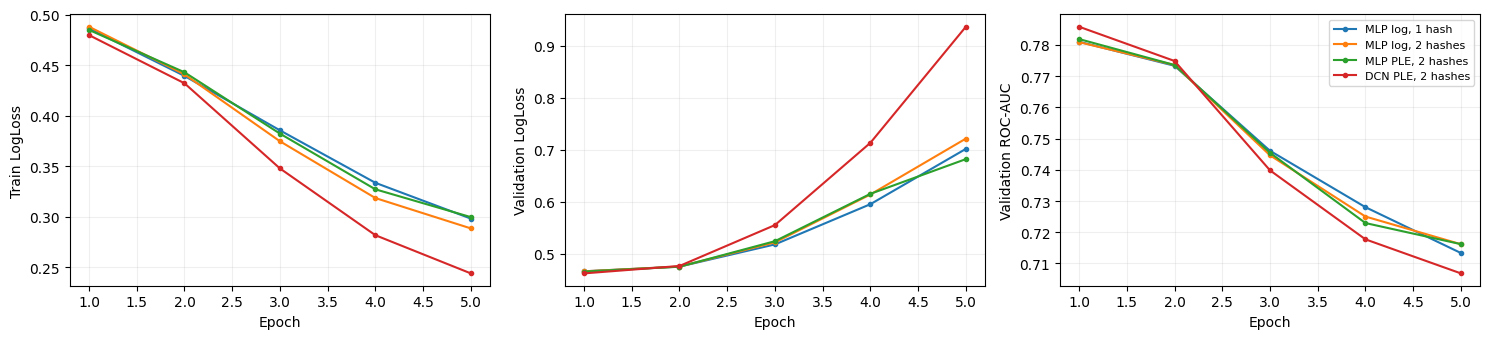

In [35]:
fig,axes=plt.subplots(1,3,figsize=(15,3.5))
for result in results:
    history=pd.DataFrame(result['history'])
    axes[0].plot(history['epoch'],history['train_loss'],marker='.',label=result['model'])
    axes[1].plot(history['epoch'],history['val_loss'],marker='.',label=result['model'])
    axes[2].plot(history['epoch'],history['ROC_AUC'],marker='.',label=result['model'])
axes[0].set(xlabel='Epoch',ylabel='Train LogLoss')
axes[1].set(xlabel='Epoch',ylabel='Validation LogLoss')
axes[2].set(xlabel='Epoch',ylabel='Validation ROC-AUC')
for ax in axes:ax.grid(alpha=.2)
axes[2].legend(fontsize=8);plt.tight_layout();plt.show()

## CatBoost

Передаём те же поля `I1–I13` и `C1–C26`. CatBoost сам обрабатывает категории,
поэтому хеши и PLE ему не нужны. Обучаем на GPU, лучшую итерацию выбираем
по ROC-AUC на validation.

В журнале CatBoost набор `eval_set` обозначен словом `test`; здесь ему
передана валидация.


In [36]:
catcols=CriteoDatasetUtils.CAT_COLS
pools={}
for name,frame in [('train',train_df),('validation',val_df),('test',test_df)]:
    # The same invertible log transform is supplied to both families.
    pools[name]=cb.Pool(frame.drop('label').to_pandas(),frame['label'].to_numpy(),cat_features=catcols)
catboost_model=cb.CatBoostClassifier(iterations=1000,depth=6,learning_rate=0.05,loss_function='Logloss',eval_metric='AUC',task_type='GPU',devices='0',gpu_ram_part=0.6,random_seed=SEED,early_stopping_rounds=80,metric_period=25,verbose=25,allow_writing_files=False)
started=time.perf_counter()
catboost_model.fit(pools['train'],eval_set=pools['validation'],use_best_model=True)
seconds=time.perf_counter()-started
pred=catboost_model.predict_proba(pools['validation'])[:,1]
test_predictions['CatBoost GPU']=catboost_model.predict_proba(pools['test'])[:,1]
results.append({'model':'CatBoost GPU','validation':metrics(val_df['label'].to_numpy(),pred),'train_seconds':seconds,'best_iteration':catboost_model.best_iteration_})
print('CatBoost validation:',json.dumps(results[-1]),flush=True)
del pools,catboost_model
gc.collect()

0:	test: 0.7181462	best: 0.7181462 (0)	total: 425ms	remaining: 7m 4s
25:	test: 0.7533662	best: 0.7533662 (25)	total: 10.2s	remaining: 6m 20s
50:	test: 0.7627514	best: 0.7627514 (50)	total: 19.3s	remaining: 5m 59s
75:	test: 0.7668931	best: 0.7668931 (75)	total: 28s	remaining: 5m 40s
100:	test: 0.7697948	best: 0.7697948 (100)	total: 36.5s	remaining: 5m 24s
125:	test: 0.7717866	best: 0.7717866 (125)	total: 44.9s	remaining: 5m 11s
150:	test: 0.7734107	best: 0.7734107 (150)	total: 53.4s	remaining: 5m
175:	test: 0.7747657	best: 0.7747657 (175)	total: 1m 1s	remaining: 4m 48s
200:	test: 0.7759480	best: 0.7759480 (200)	total: 1m 9s	remaining: 4m 37s
225:	test: 0.7769382	best: 0.7769382 (225)	total: 1m 18s	remaining: 4m 28s
250:	test: 0.7778026	best: 0.7778026 (250)	total: 1m 26s	remaining: 4m 18s
275:	test: 0.7785653	best: 0.7785653 (275)	total: 1m 35s	remaining: 4m 9s
300:	test: 0.7793431	best: 0.7793431 (300)	total: 1m 43s	remaining: 4m
325:	test: 0.7800796	best: 0.7800796 (325)	total: 1m 52s

9315

## Сравнение на валидации

В таблице — метрики выбранной эпохи или итерации. Время включает обучение
и проверку валидации, время подготовки признаков сюда не входит.


In [37]:
validation_table=pd.DataFrame([{'model':r['model'],**r['validation'],'seconds':r['train_seconds'],'parameters':r.get('parameters'),'selected_step':r.get('best_epoch',r.get('best_iteration'))} for r in results])
display(validation_table.round(4))

,model,ROC_AUC,AP,LogLoss,seconds,parameters,selected_step
0,"MLP log, 1 hash",0.7810,0.5671,0.4663,7.5403,2240257.0,1
1,"MLP log, 2 hashes",0.7809,0.5672,0.4663,7.4812,2346753.0,1
2,"MLP PLE, 2 hashes",0.7819,0.5682,0.4658,7.7212,2396673.0,1
3,"DCN PLE, 2 hashes",0.7858,0.5750,0.4623,38.9882,4561953.0,1
4,CatBoost GPU,0.7864,0.5775,0.4617,369.3677,NaN,999


## Проверка на следующем дне

Посчитаем ROC-AUC, Average Precision и LogLoss на тестовом файле.
Используем уже выбранные веса.


,model,ROC_AUC,AP,LogLoss,seconds
0,"MLP log, 1 hash",0.7799,0.5668,0.4698,7.5403
1,"MLP log, 2 hashes",0.7794,0.5663,0.4701,7.4812
2,"MLP PLE, 2 hashes",0.7807,0.5677,0.4694,7.7212
3,"DCN PLE, 2 hashes",0.7844,0.5739,0.4662,38.9882
4,CatBoost GPU,0.7847,0.5751,0.4661,369.3677


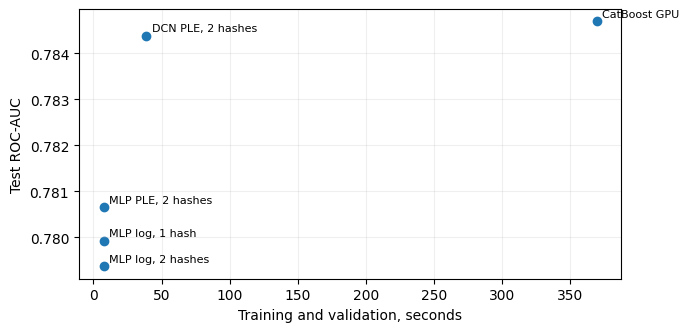

GPU_RUN_COMPLETE


In [38]:
for result in results:
    result['test']=metrics(y_test,test_predictions[result['model']])
test_table=pd.DataFrame([{'model':r['model'],**r['test'],'seconds':r['train_seconds']} for r in results])
display(test_table.round(4))
fig,ax=plt.subplots(figsize=(7,3.5))
ax.scatter(test_table['seconds'],test_table['ROC_AUC'])
for row in test_table.itertuples():ax.annotate(row.model,(row.seconds,row.ROC_AUC),fontsize=8,xytext=(4,3),textcoords='offset points')
ax.set(xlabel='Training and validation, seconds',ylabel='Test ROC-AUC');ax.grid(alpha=.2);plt.show()
report={'seed':SEED,'train_rows':len(train_df),'validation_rows':len(val_df),'test_rows':len(test_df),'gpu':torch.cuda.get_device_name(0),'python':platform.python_version(),'torch':torch.__version__,'polars':pl.__version__,'catboost':cb.__version__,'results':results}
Path('benchmark_results.json').write_text(json.dumps(report,ensure_ascii=False,indent=2))
print('GPU_RUN_COMPLETE')

## Результаты

В прогоне на T4 с 1 млн обучающих показов DCN получила тестовый ROC-AUC
0,7844, MLP с PLE — 0,7807. Добавление двух cross-слоёв дало 0,0037 ROC-AUC.
CatBoost получил 0,7847; AP составила 0,5751 против 0,5739 у DCN.

Пять эпох DCN с проверкой validation заняли 39 с, CatBoost — 369 с.
Подготовка признаков в это время не входит. У всех четырёх нейросетей
лучшей осталась первая эпоха: дальше train loss снижался, а validation
loss рос и ROC-AUC ухудшался. Это видно на кривых обучения.

При увеличении train с 600 тыс. до 1 млн тестовый ROC-AUC DCN вырос
с 0,7794 до 0,7844, CatBoost — с 0,7814 до 0,7847. Тестовая выборка та же;
train и validation заново сформированы из увеличенной выборки.


## Extra: low-rank cross

В `TabularRanker(..., rank=32)` полная cross-матрица заменяется произведением
двух матриц. Вместо $d^2$ весов нужно $2dr$. Следующая ячейка проверяет
прямой и обратный проход такого слоя на GPU.


In [39]:
# Конструкция и обратный проход: проверяем совместимость с текущим GPU.
probe=TabularRanker(13,hashes=2,cross_layers=2,rank=32).to(device)
probe_logits=probe(torch.zeros(8,13,device=device),torch.zeros(8,52,dtype=torch.long,device=device))
nn.BCEWithLogitsLoss()(probe_logits,torch.zeros(8,device=device)).backward()
assert all(p.grad is not None and torch.isfinite(p.grad).all() for p in probe.parameters())
print('Low-rank GPU forward/backward: PASS')
del probe;gc.collect();torch.cuda.empty_cache()

Low-rank GPU forward/backward: PASS
